# 03 · Signatures — Cohen et al. 2021 Multiple Myeloma

Score the three embryonic modules — **Gast** (gastrulation), **pSom** (posterior somitogenesis),
**Crest** (neural crest) — with `score_genes` against the **union control pool**, and read **Gate 2**
off the module geography. The panels show **raw per-cell scores** (the honest deliverable readout).

**Gate 2 (GO / non-branching):** the modules resolve onto a single developmental axis — a Gast/pSom-high
origin grading to a Crest-high terminus. Gast and pSom mildly co-vary (smoothed r=+0.28, overlap not
opposition) and both are inversely opposed by Crest (r=-0.73, -0.65): there are **no two competing arms**
and no Gast/pSom hub diverging into a Y. Crest is an **inverse terminal gradient** — the canonical
non-branching case (§1). No Crest-on-Gast-arm inversion to flag. Deliverable: `signatures.h5ad`,
`{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [1]:
import os, glob, warnings
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sc.settings.verbosity = 1

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_out, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)

In [3]:
# load manifold data; scores were computed in 01 with the union control pool. Re-affirm here on the
# manifold h5ad so this notebook is self-contained and reproduces the reported raw module means.
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad'))
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, l in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=list(g), score_name=l, ctrl_as_ref=False,
                      gene_pool=list(g_ref), random_state=1234)
    print('%s: %d/%d genes' % (l, g.size, feat[src].size))
print('GLOBAL raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
# use the house linear layout for all deliverable panels
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']

Gast: 69/81 genes
pSom: 80/98 genes
Crest: 101/104 genes
GLOBAL raw module means: {'Gast': -0.0217, 'pSom': 0.0144, 'Crest': 0.0013}


In [4]:
# reusable house (3.5,1.5) signature-panel renderer: raw per-cell scores, plasma cmap, external colorbar.
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
def sig_panel(col, title, cbtitle, ticks, fn_fig, fn_cb):
    fig, ax = plt.subplots(figsize=(3.5, 1.5))
    sc.pl.umap(adata, color=col, cmap='plasma', alpha=.6, size=12, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
    ax.text(.5, -.14, 'Cohen et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(fn_fig, bbox_inches='tight')
    # external colorbar (separate file)
    figc = plt.figure(figsize=(.66, 1)); cax = figc.add_axes([.35, .05, .3, .9])
    cb = plt.colorbar(ax.collections[0], cax=cax)
    cb.ax.tick_params(which='both', size=0); cb.set_label(cbtitle)
    cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    figc.savefig(fn_cb, bbox_inches='tight')
    plt.show()
print('panel renderer ready')

panel renderer ready


saved Gast_signature.pdf + colorbar


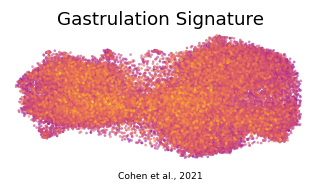

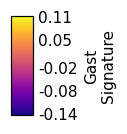

In [5]:
# Gastrulation signature (raw)
q = np.round(np.quantile(adata.obs['Gast'], [0, .25, .5, .75, 1]), 2)
sig_panel('Gast', 'Gastrulation Signature', 'Gast\nSignature', list(np.round(np.linspace(q[0], q[-1], 5), 2)),
          os.path.join(pth_out, 'Gast_signature.pdf'), os.path.join(pth_cb, 'Gast_colorbar.pdf'))
print('saved Gast_signature.pdf + colorbar')

saved pSom_signature.pdf + colorbar


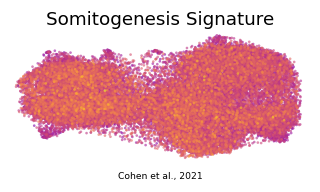

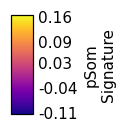

In [6]:
# Somitogenesis (pSom) signature (raw)
q = np.round(np.quantile(adata.obs['pSom'], [0, .25, .5, .75, 1]), 2)
sig_panel('pSom', 'Somitogenesis Signature', 'pSom\nSignature', list(np.round(np.linspace(q[0], q[-1], 5), 2)),
          os.path.join(pth_out, 'pSom_signature.pdf'), os.path.join(pth_cb, 'pSom_colorbar.pdf'))
print('saved pSom_signature.pdf + colorbar')

saved Crest_signature.pdf + colorbar


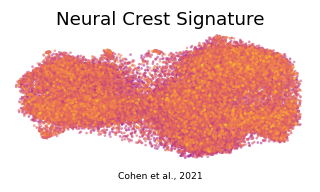

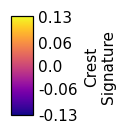

In [7]:
# Neural Crest signature (raw)
q = np.round(np.quantile(adata.obs['Crest'], [0, .25, .5, .75, 1]), 2)
sig_panel('Crest', 'Neural Crest Signature', 'Crest\nSignature', list(np.round(np.linspace(q[0], q[-1], 5), 2)),
          os.path.join(pth_out, 'Crest_signature.pdf'), os.path.join(pth_cb, 'Crest_colorbar.pdf'))
print('saved Crest_signature.pdf + colorbar')

In [8]:
# Gate-2 readout summary
print('smoothed geography: Gast-pSom r=%+.2f | Gast-Crest r=%+.2f | pSom-Crest r=%+.2f'
      % (np.corrcoef(adata.obs.Gast_sm, adata.obs.pSom_sm)[0,1],
         np.corrcoef(adata.obs.Gast_sm, adata.obs.Crest_sm)[0,1],
         np.corrcoef(adata.obs.pSom_sm, adata.obs.Crest_sm)[0,1]))
print('GATE 2 = GO (non-branching): single Gast/pSom-origin -> Crest-terminus axis; no two competing '
      'arms, no hub bifurcation. Crest is an inverse terminal gradient (not on a Gast arm -> no flag).')
adata.write(os.path.join(pth_in, 'signatures.h5ad'))
print('saved signatures.h5ad')

smoothed geography: Gast-pSom r=+0.28 | Gast-Crest r=-0.73 | pSom-Crest r=-0.65
GATE 2 = GO (non-branching): single Gast/pSom-origin -> Crest-terminus axis; no two competing arms, no hub bifurcation. Crest is an inverse terminal gradient (not on a Gast arm -> no flag).
saved signatures.h5ad
